In [8]:
from yellowbrick.cluster import SilhouetteVisualizer
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '12'


In [ ]:
# DATA MINING 1





# Stile generale per i grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# CARICAMENTO DATAFRAME
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")


# -----------------------------------------------
# -----------------------------------------------
# PULIZIA BASE E DEFINIZIONE GRUPPI DI COLONNE

print(f"\n----PULIZIA----")

df_cleaned = df.copy()
# Dropping delle variabili inutili
df_cleaned = df_cleaned.drop(["ComWeight", "LanguageEase", "BestPlayers", "GoodPlayers",
                              "ComMaxPlaytime", "NumComments", "ImagePath"], axis=1)
#Tolte ComWeight (uguale altra variabile), LanguageEase (non si capisce a cosa serva), BestPlayers (praticamente solo valori mancanti), GoodPlayers (come bestplayers),
# ComMaxPlaytime (= a mfgplaytime), NumComments (tutti 0), ImagePath")

# Filtro dei valori errati = 0 non imputabili
df_cleaned = df_cleaned[df_cleaned["YearPublished"] != 0]
df_cleaned = df_cleaned[df_cleaned["MinPlayers"] != 0]
df_cleaned = df_cleaned[df_cleaned["MaxPlayers"] != 0]

# Gestione NA di Family
df_cleaned["Family"] = df_cleaned["Family"].fillna("No_Family")

# Missing values di Gameweight
df_cleaned["GameWeight"] = df_cleaned["GameWeight"].replace(0, np.nan)

print(f"\n----------")

df_cleaned.info()

print(f"\n----------")

# IDEA CHIAVE: alla fine non abbiamo basi che ci permettono di rimuovere gli outliers tipo catan o Monopoli
# Però, possiamo pensare a year_published

# Colonna "Period"
condizione = [
    (df_cleaned['YearPublished'] < 1000),
    (df_cleaned['YearPublished'] >= 1000) & (
        df_cleaned['YearPublished'] < 1900),
    (df_cleaned['YearPublished'] >= 1900) & (
        df_cleaned['YearPublished'] < 2000),
    (df_cleaned['YearPublished'] >= 2000) & (
        df_cleaned['YearPublished'] < 2010),
    (df_cleaned['YearPublished'] >= 2010)
]
epoca = [
    'Pre_1000',
    '1000_1900',
    '1900_2000',
    '2000_2010',
    "2010_2021"
]
df_cleaned['Period'] = np.select(condizione, epoca, default=None)

# Colonna "Age"
df_cleaned['Age'] = 2025 - df_cleaned["YearPublished"]

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns
colonne_quanti = colonne_quanti.drop([
    "BGGId"] + colonne_binarie
    + colonne_rank + colonne_cat)

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist() +
    colonne_rank +
    colonne_cat +
    colonne_binarie
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

# Creazione train_set e test_set per Data Leakage 
#da farmi spiegare cosa è stato fatto
train_set, test_set = train_test_split(
    df_cleaned, test_size=0.2, random_state=222)
train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")
 

# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS

print(f"\n----OUTLIERS MODA----")

# Gestione missing con moda (valore di moda anche = a mediana quindi conveniente usare questo)
mode_mfg_playtime = train_set["MfgPlaytime"].mode()[0]
train_set["MfgPlaytime"] = train_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)
test_set["MfgPlaytime"] = test_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)

mode_com_playtime = train_set["ComMinPlaytime"].mode()[0]
train_set["ComMinPlaytime"] = train_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)
test_set["ComMinPlaytime"] = test_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)

# IMPUTAZIONE RANDOM FOREST
# Non c'è bisogno di scalare perchè gode di Invarianza Monotona

print(f"\n----OUTLIERS RANDOM FOREST----")

rf_estimator = RandomForestRegressor(
    n_estimators=22,
    random_state=222,
    n_jobs=-1
)

imputer_rf = IterativeImputer(
    estimator=rf_estimator,
    max_iter=10,
    random_state=222,
    verbose=2,               # 0 = silente, 1 = output, 2 = output dettagliato
    initial_strategy='median',
    add_indicator=False
)

df_numeric_to_impute = df_cleaned[colonne_numeriche].copy()

imputer_rf.fit(train_set[colonne_numeriche])
imputed_array_train = imputer_rf.transform(train_set[colonne_numeriche])
imputed_array_test = imputer_rf.transform(test_set[colonne_numeriche])

train_imputed = train_set.copy()
test_imputed = test_set.copy()

train_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_train,
    columns=colonne_numeriche,
    index=train_imputed.index
)
test_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_test,
    columns=colonne_numeriche,
    index=test_imputed.index
)


# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI (SKEWNESS)

print(f"\n----TRASFORMAZIONE----")


def fit_trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0):

    skew_values = dataframe[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:
        if dataframe[col].isnull().any():
            print(f"\n  - ATTENZIONE: '{col}' contiene NaN, non dovrebbe.")
            continue

        if dataframe[col].min() < 0:
            col_cbrt.append(col)
        else:
            col_log.append(col)

    if col_log:
        print(f"\n  - Trasformazione Logaritmica identificata per: {col_log}")
    if col_cbrt:
        print(
            f"\n  - Trasformazione Radice Cubica identificata per: {col_cbrt}")

    return col_log, col_cbrt


def apply_trasformatore(dataframe: pd.DataFrame, col_log: list, col_cbrt: list):
    df_copy = dataframe.copy()

    for col in col_log:
        if col in df_copy.columns:
            df_copy[col] = np.log1p(df_copy[col])

    for col in col_cbrt:
        if col in df_copy.columns:
            df_copy[col] = np.cbrt(df_copy[col])

    return df_copy


colonne_log, colonne_cbrt = fit_trasformatore(
    train_imputed, colonne_quanti.tolist())

train_transformed = apply_trasformatore(
    train_imputed, colonne_log, colonne_cbrt)
test_transformed = apply_trasformatore(test_imputed, colonne_log, colonne_cbrt)


# -----------------------------------------------
# -----------------------------------------------
# CORRELAZIONE

print("\n----CORRELAZIONE----")

# NON Trasformati
df_numeric_imputed = train_imputed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_imputed = df_numeric_imputed.corr()

# Trasformati
df_numeric_transformed = train_transformed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_transformed = df_numeric_transformed.corr()



----PULIZIA----

----------
<class 'pandas.core.frame.DataFrame'>
Index: 21564 entries, 0 to 21924
Data columns (total 39 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   BGGId                21564 non-null  int64  
 1   Name                 21564 non-null  object 
 2   Description          21563 non-null  object 
 3   YearPublished        21564 non-null  int64  
 4   GameWeight           21082 non-null  float64
 5   MinPlayers           21564 non-null  int64  
 6   MaxPlayers           21564 non-null  int64  
 7   ComAgeRec            16185 non-null  float64
 8   NumOwned             21564 non-null  int64  
 9   NumWant              21564 non-null  int64  
 10  NumWish              21564 non-null  int64  
 11  NumWeightVotes       21564 non-null  int64  
 12  MfgPlaytime          21564 non-null  int64  
 13  ComMinPlaytime       21564 non-null  int64  
 14  MfgAgeRec            21564 non-null  int64  
 15  NumUserRatin

In [2]:
# CLUSTERING

print("\n----CLUSTERING----")

X = train_transformed[colonne_numeriche]
y = np.array(train_transformed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

# -----------------------------------------------
# K-means
print("\n----CLUSTERING (K-Means)----")

kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

# -----------------------------------------------
# Bisecting K-means
print("\n----CLUSTERING (Bisecting K-Means)----")

bkmeans = BisectingKMeans(n_clusters=5, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

# -----------------------------------------------
# DBscan
print("\n----CLUSTERING (DBscan)----")

dbscan = DBSCAN(eps=0.01, min_samples=10)
dbscan.fit(X_minmax)

# -----------------------------------------------
# Optics
print("\n----CLUSTERING (Optics)----")

optics = OPTICS(min_samples=20, max_eps=np.inf, min_cluster_size=10)
optics.fit(X_minmax)

# -----------------------------------------------
# Gerarchico
print("\n----CLUSTERING (Gerarchico)----")


def get_linkage_matrix(model):
    # Create linkage matrix

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix


def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)


model = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                metric='euclidean', linkage='complete')
model = model.fit(X_minmax)

# Finire pulizia                                        FATTO
# Scegliere variabili su cui fare clustering            DAFARE
# Giocare coi parametri di clustering                   DAFARE


----CLUSTERING----

----CLUSTERING (K-Means)----

----CLUSTERING (Bisecting K-Means)----

----CLUSTERING (DBscan)----

----CLUSTERING (Optics)----

----CLUSTERING (Gerarchico)----


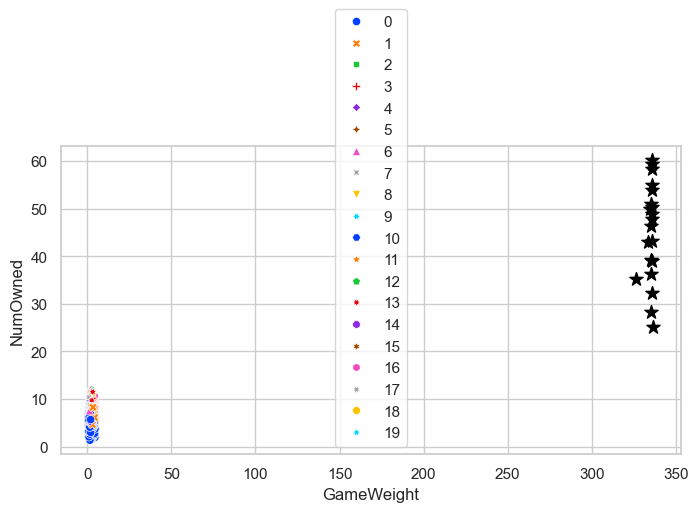

In [3]:
# -----------------------------------------------
# X-means
from pyclustering.cluster import xmeans
xm = xmeans.xmeans(X)
xm.process()
clusters = xm.get_clusters()

def clusters_to_labels(clusters):
    labels = np.empty(shape=(len(np.concatenate(clusters))), dtype=int)
    for i in range(len(clusters)):
        for idx in clusters[i]:
            labels[idx] = i
    return labels

labels = clusters_to_labels(clusters)
centers = np.array(xm.get_centers())
centers_unscaled = scaler.inverse_transform(centers)

sns.scatterplot(data=train_transformed, x="GameWeight",
                y="NumOwned", hue=labels, palette="bright", style=labels)
plt.scatter(centers_unscaled[:, 0], centers_unscaled[:,7], color="black", marker="*", s=100)
plt.show()

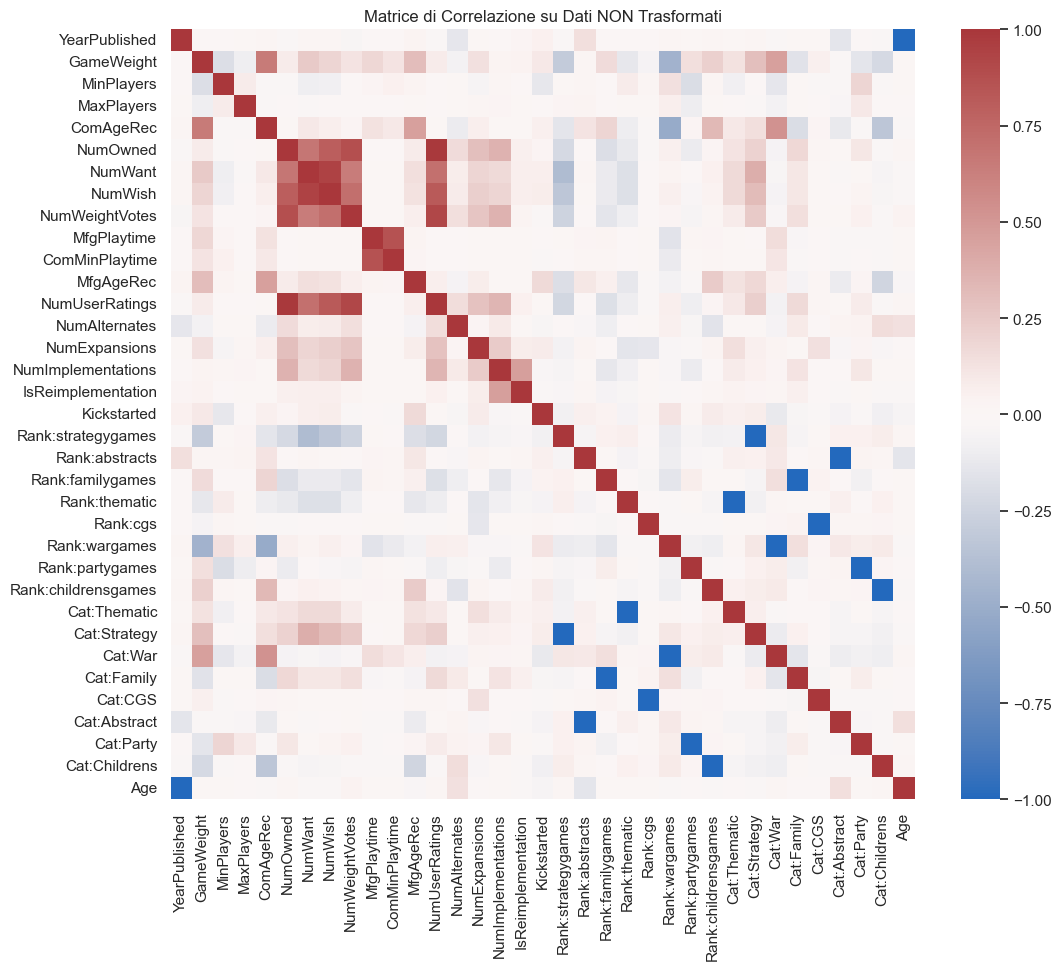

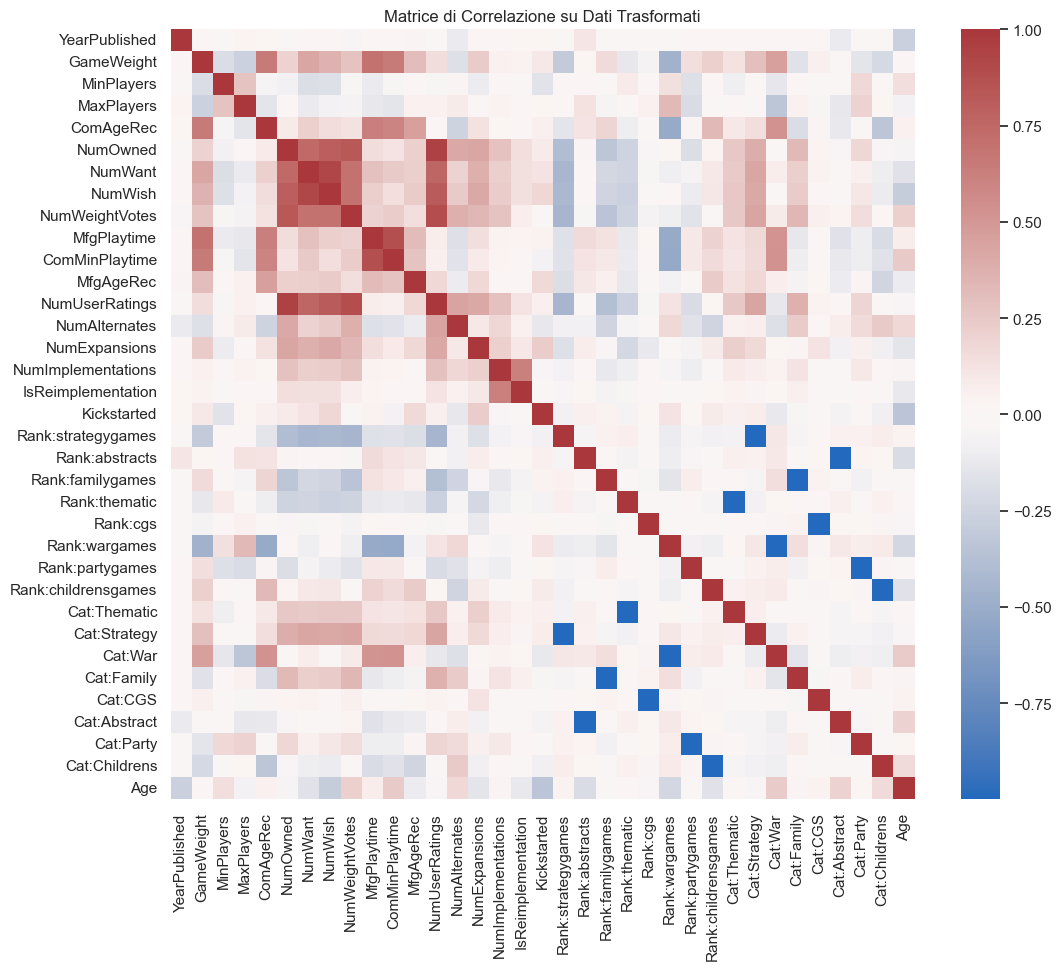

In [4]:
# Grafici Correlazione

plt.rcParams['figure.figsize'] = (8, 4)

plt.figure(figsize=(12, 10))
sns.heatmap(M_Cor_imputed, annot=False, cmap='vlag', fmt=".2f")
plt.title("Matrice di Correlazione su Dati NON Trasformati")
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(M_Cor_transformed, annot=False, cmap='vlag', fmt=".2f")
plt.title("Matrice di Correlazione su Dati Trasformati")
plt.show()

CPU times: user 6min 29s, sys: 6min 19s, total: 12min 49s
Wall time: 1min 12s


<Axes: >

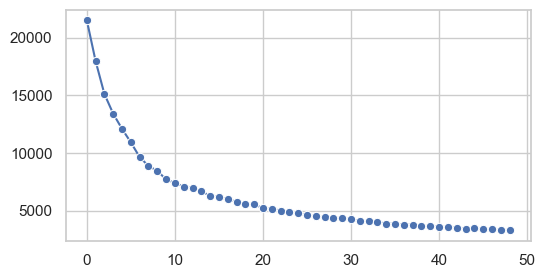

In [5]:
%%time
sse_list = []
plt.rcParams['figure.figsize'] = (6, 3)

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(X_minmax)
    sse_list.append(kmeans.inertia_)
    sse_list

sse_list
sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o')




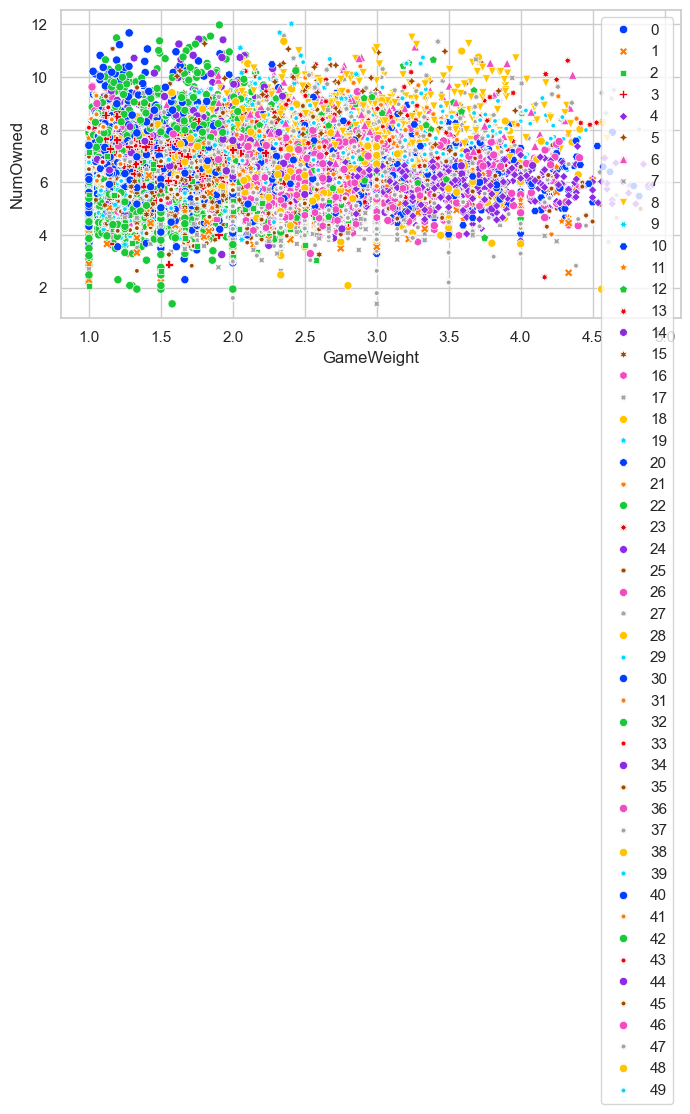

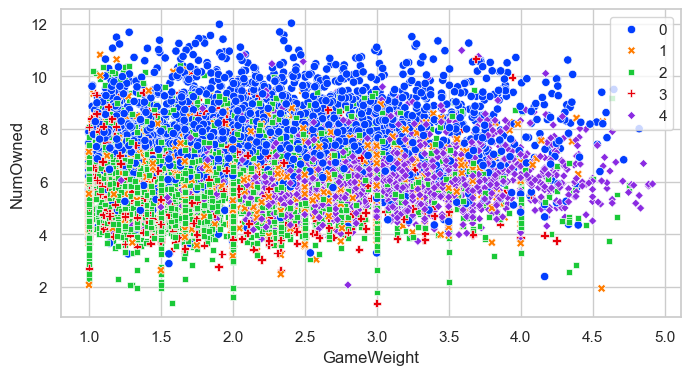

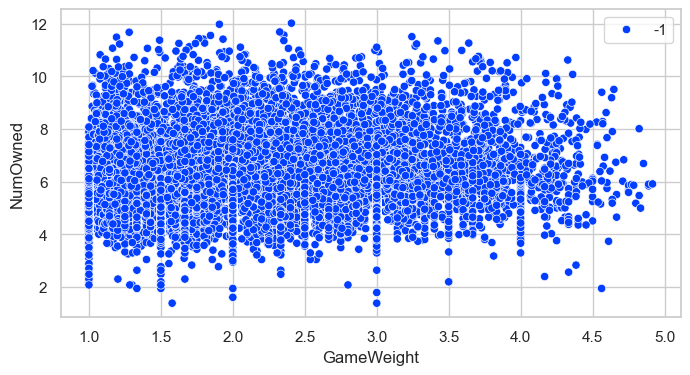

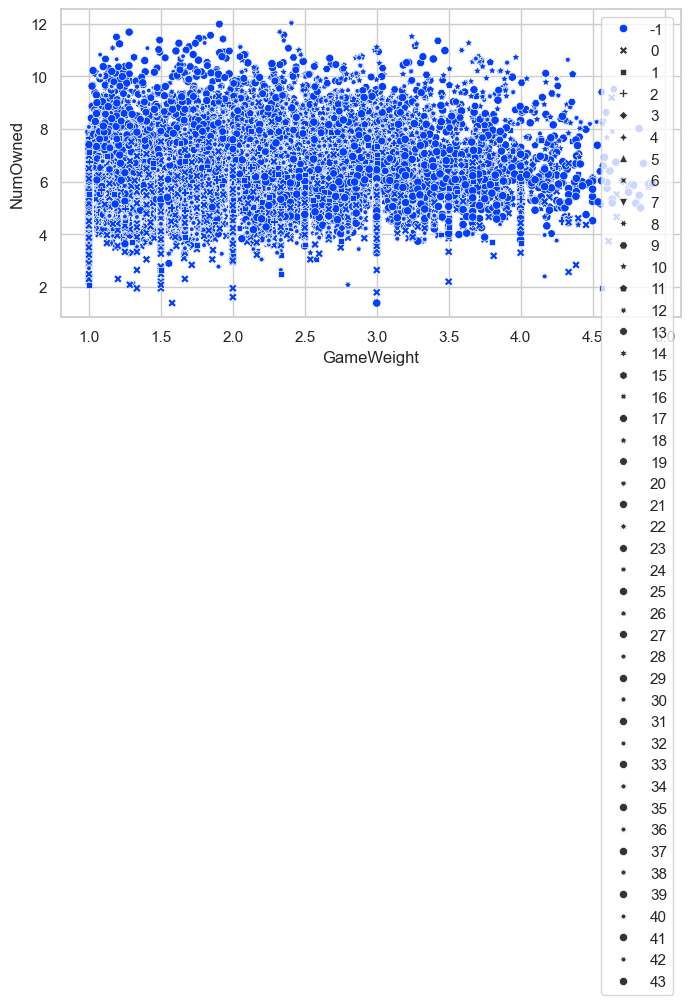

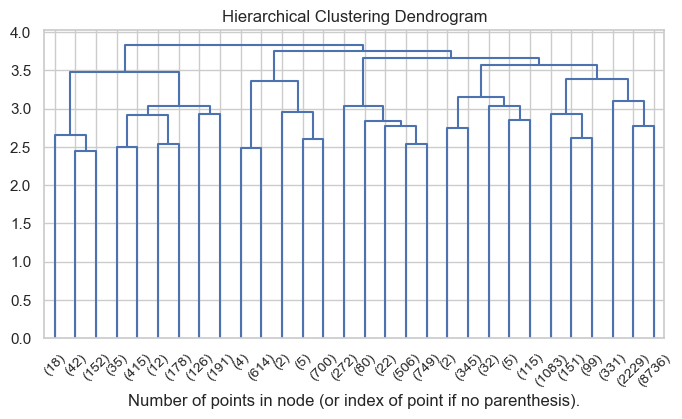

In [6]:
plt.rcParams['figure.figsize'] = (8, 4)

#kmeans scatter
sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright",
                )
plt.legend()
plt.show()


sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=dbscan.labels_,
                style=dbscan.labels_,
                palette="bright")
plt.show()

sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=dbscan.labels_,
                style=optics.labels_,
                palette="bright")
plt.show()


plt.title("Hierarchical Clustering Dendrogram")
plot_dendrogram(model, truncate_mode='lastp', color_threshold=0.7)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

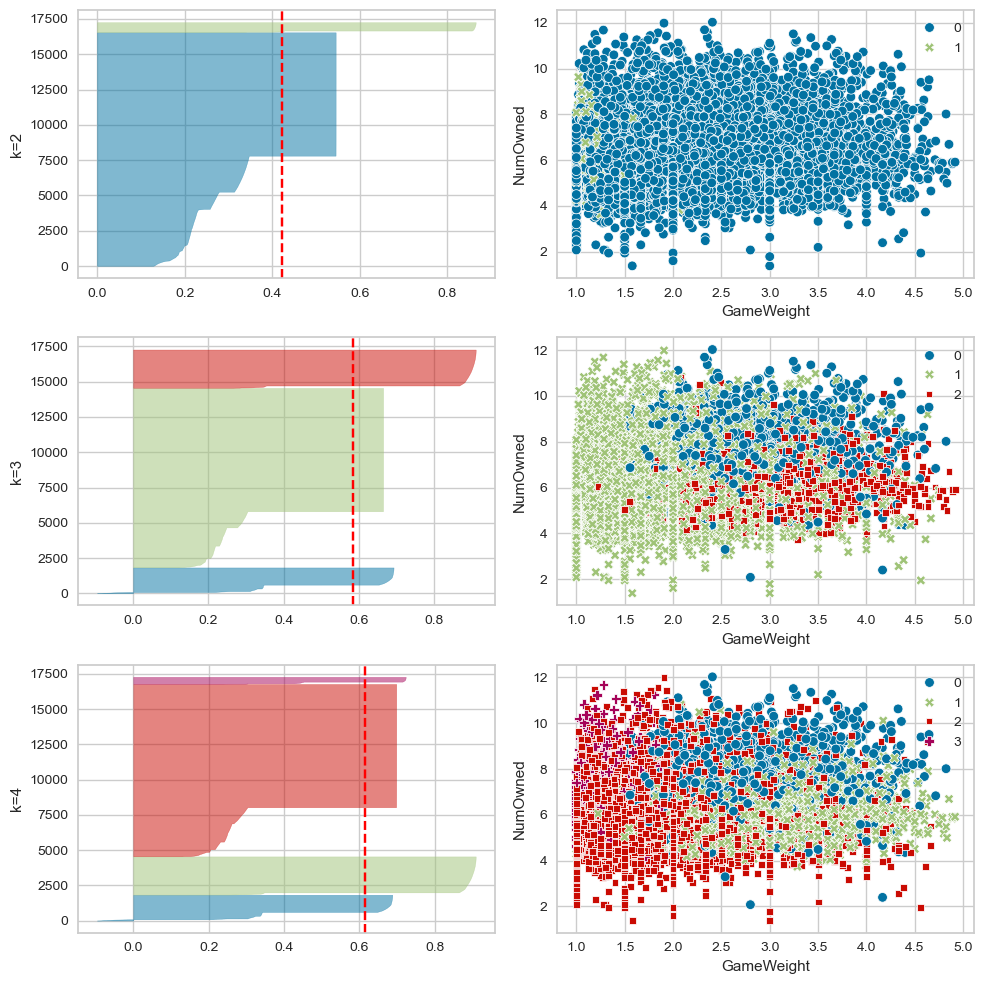

In [ ]:

colors=['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
n_clust = 5
fig, axs = plt.subplots(n_clust-2, 2, figsize=(10,10))
for i in range(2, n_clust):
    bkmeans = BisectingKMeans(n_clusters=i)
    visualizer = SilhouetteVisualizer(bkmeans, colors=colors, ax=axs[i-2][0])
    axs[i-2][0].set_ylabel("k=" + str(i))
    visualizer.fit(X)
    sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned", hue=bkmeans.labels_,
                    palette=sns.color_palette(colors[:i]), style=bkmeans.labels_, ax=axs[i-2][1])
plt.tight_layout()


In [10]:
silhouette_score(X, bkmeans.labels_)

np.float64(0.6141517467687797)

In [22]:

# -----------------------------------------------
# -----------------------------------------------
#CLUSTERING CENTROID-BASED


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd # Assicurati che pandas sia importato
'''
#1. Definisci le colonne che vuoi scalare
colonne_numeriche = df_corretto.select_dtypes(include=["int64", "float64"]).columns

colonne_da_escludere = [
    "BGGId",
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames", "Rank:partygames",
    "Rank:childrensgames", "Cat:Thematic", "Cat:Strategy", "Cat:War",
    "Cat:Family", "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens",
    "Kickstarted", "IsReimplementation", "ComAgeRec"
]

#errors='ignore'' evita un errore se una colonna da escludere non è tra quelle numeriche
colonne_da_scalare = colonne_numeriche.drop(colonne_da_escludere, errors='ignore')'''

'''2. Seleziona i DATI da quelle colonne
Questa è la parte che mancava:'''
X= train_transformed[colonne_numeriche]

#3. Inizializza lo scaler e adatta i DATI (X), non la lista dei nomi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#(Opzionale, ma utile) Puoi riconvertire l'array scalato in un DataFrame
X_scaled_df = pd.DataFrame(X_scaled, columns=colonne_numeriche, index=X.index)
'''4. Applica la PCA
Questa parte era già corretta'''
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

import matplotlib.pyplot as plt
import seaborn as sns # <-- 1. Assicurati di importare Seaborn

'''--- 2. Crea un nuovo DataFrame per il plotting ---
Questo rende il plotting con Seaborn molto più semplice
Crea il DataFrame con i risultati della PCA'''
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2','PC3'])

'''Aggiungi la colonna per il colore dal tuo DataFrame originale
USA IL NOME CORRETTO DELLA COLONNA CHE VUOI USARE PER I COLORI
(Sostituisci 'NOME_COLONNA_PER_COLORE' con 'outliers', 'cluster', ecc.)
Usiamo l'indice di 'X' per garantire che le righe corrispondano'''
total_explained_variance = np.sum(pca.explained_variance_ratio_)
k = 2
print(f"\nVarianza totale spiegata dalle {k} componenti: {total_explained_variance * 100:.2f}%")

pca_df['colore'] = train_transformed.loc[X.index, 'outlier'].values

#--- 3. Calcola la varianza (già fatto da te) ---
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100

#--- 4. Disegna il grafico con Seaborn (ora con i dati!) ---
plt.figure(figsize=(10, 7)) # Imposta una dimensione leggibile

sns.scatterplot(
    data=pca_df,       # Usa il DataFrame appena creato
    x='PC1',           # Colonna per l'asse X
    y='PC2',           # Colonna per l'asse Y
    hue='colore',      # Colonna per definire i colori
    palette='viridis', # Mappa colori (puoi cambiarla)
    s=50,              # Dimensione dei punti
    alpha=0.7          # Trasparenza
)

#Aggiungi etichette e titolo (il tuo codice era già corretto)
plt.xlabel(f'Principal Component 1 ({pc1_variance:.2f}%)')
plt.ylabel(f'Principal Component 2 ({pc2_variance:.2f}%)')
plt.title('PCA del Game Dataset')
plt.grid()
plt.show()

'''import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Necessario per projection='3d'

# 5. Visualizza i risultati in 3D (se PCA è stata fatta con n_components=3)
fig = plt.figure(figsize=(10, 8))  # Un po' più grande per il 3D
ax = fig.add_subplot(111, projection='3d') # Crea assi 3D

# --- CORREZIONE: Usa ax.scatter e includi la terza dimensione ---
# X_pca[:, 0] -> asse x
# X_pca[:, 1] -> asse y
# X_pca[:, 2] -> asse z
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], alpha=0.5)

# Calcola la varianza per TUTTE E 3 le componenti
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100
pc3_variance = pca.explained_variance_ratio_[2] * 100 # Questa riga era già corretta

# --- CORREZIONE: Usa ax.set_xlabel, ax.set_ylabel, e ax.set_zlabel ---
ax.set_xlabel(f'Principal Component 1 ({pc1_variance:.2f}%)')
ax.set_ylabel(f'Principal Component 2 ({pc2_variance:.2f}%)')
ax.set_zlabel(f'Principal Component 3 ({pc3_variance:.2f}%)')

ax.set_title('PCA del Game Dataset (3D)')
# ax.grid(True) # Il grid è solitamente attivo di default in 3D
plt.show()
'''


Varianza totale spiegata dalle 2 componenti: 38.94%


KeyError: 'outlier'


---- PCA: ANALISI DELLE COMPONENTI PRINCIPALI ----
Dati pronti per la PCA con shape: (17251, 36)


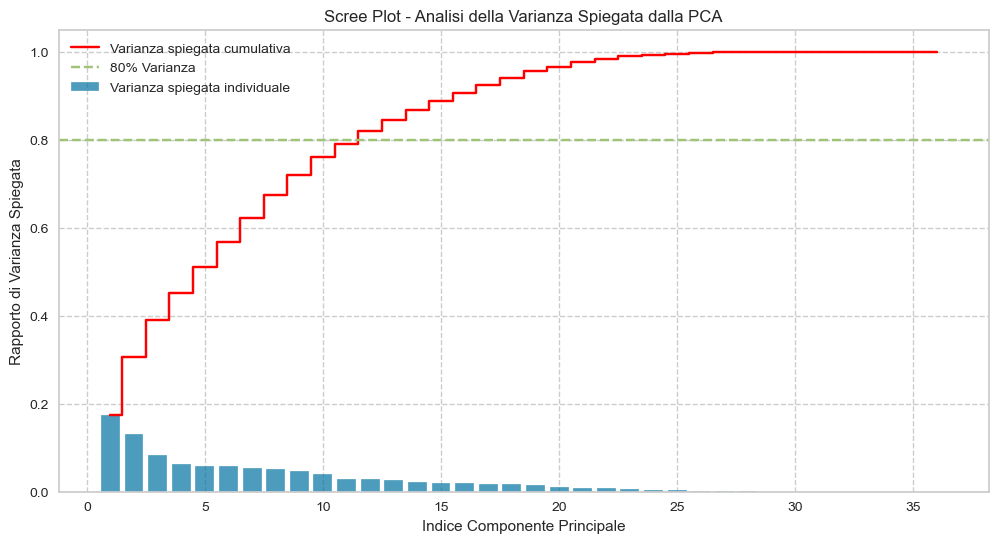


Numero di componenti per spiegare almeno l'80% della varianza: 12
Dimensioni del dataset dopo la PCA: (17251, 12)


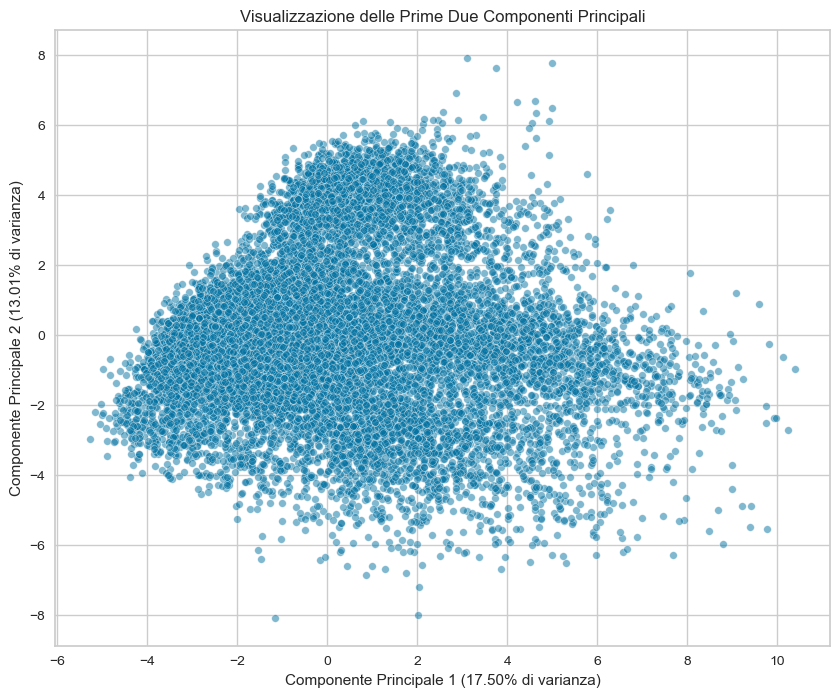

In [ ]:
# ===============================================
# ===============================================
# ANALISI DELLE COMPONENTI PRINCIPALI (PCA)
# ===============================================

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("\n---- PCA: ANALISI DELLE COMPONENTI PRINCIPALI ----")

# 1. SELEZIONE E SCALATURA DEI DATI
# Usiamo il set di dati già imputato e trasformato (train_transformed)
# e selezioniamo solo le colonne numeriche che hai definito in precedenza.
X_train = train_transformed[colonne_numeriche]

# La PCA è sensibile alla scala delle variabili, quindi standardizziamo i dati
# per avere media 0 e deviazione standard 1.
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)

print(f"Dati pronti per la PCA con shape: {X_train_scaled.shape}")


# 2. ANALISI DELLA VARIANZA SPIEGATA (PER DECIDERE QUANTE COMPONENTI TENERE)
# Applichiamo la PCA senza specificare n_components per calcolarle tutte.
pca_analisi = PCA()
pca_analisi.fit(X_train_scaled)

# Calcoliamo la varianza spiegata cumulativa
varianza_cumulativa = np.cumsum(pca_analisi.explained_variance_ratio_)

# Creiamo un grafico (Scree Plot) per visualizzare la varianza
plt.figure(figsize=(12, 6))
plt.bar(range(1, len(varianza_cumulativa) + 1), pca_analisi.explained_variance_ratio_, alpha=0.7, align='center',
        label='Varianza spiegata individuale')
plt.step(range(1, len(varianza_cumulativa) + 1), varianza_cumulativa, where='mid',
         label='Varianza spiegata cumulativa', color='red')
plt.ylabel('Rapporto di Varianza Spiegata')
plt.xlabel('Indice Componente Principale')
plt.title('Scree Plot - Analisi della Varianza Spiegata dalla PCA')
plt.legend(loc='best')
plt.grid(True, which='both', linestyle='--')
# Aggiungiamo una linea per l'80% di varianza, un target comune
plt.axhline(y=0.8, color='g', linestyle='--', label='80% Varianza')
plt.legend(loc='best')
plt.show()

# Troviamo il numero di componenti per spiegare almeno l'80% della varianza
n_components_80_var = np.where(varianza_cumulativa >= 0.80)[0][0] + 1
print(f"\nNumero di componenti per spiegare almeno l'80% della varianza: {n_components_80_var}")


# 3. APPLICAZIONE DELLA PCA FINALE CON IL NUMERO DI COMPONENTI SCELTO
# Scegliamo un numero di componenti (es. quello trovato sopra o un altro valore)
k = n_components_80_var
pca_finale = PCA(n_components=k)

# Applichiamo la PCA ai dati scalati per ottenere il dataset ridotto
X_train_pca = pca_finale.fit_transform(X_train_scaled)

print(f"Dimensioni del dataset dopo la PCA: {X_train_pca.shape}")


# 4. VISUALIZZAZIONE DELLE PRIME DUE COMPONENTI PRINCIPALI
# Creiamo un DataFrame con i risultati della PCA per plottare più facilmente
pca_df = pd.DataFrame(data=X_train_pca[:, :2], columns=['PC1', 'PC2'])

# Calcoliamo la varianza per le etichette del grafico
pc1_variance = pca_finale.explained_variance_ratio_[0] * 100
pc2_variance = pca_finale.explained_variance_ratio_[1] * 100

# Creiamo lo scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    alpha=0.5, # Trasparenza per vedere la densità dei punti
    s=30       # Dimensione dei punti
)

plt.title('Visualizzazione delle Prime Due Componenti Principali')
plt.xlabel(f'Componente Principale 1 ({pc1_variance:.2f}% di varianza)')
plt.ylabel(f'Componente Principale 2 ({pc2_variance:.2f}% di varianza)')
plt.grid(True)
plt.show()


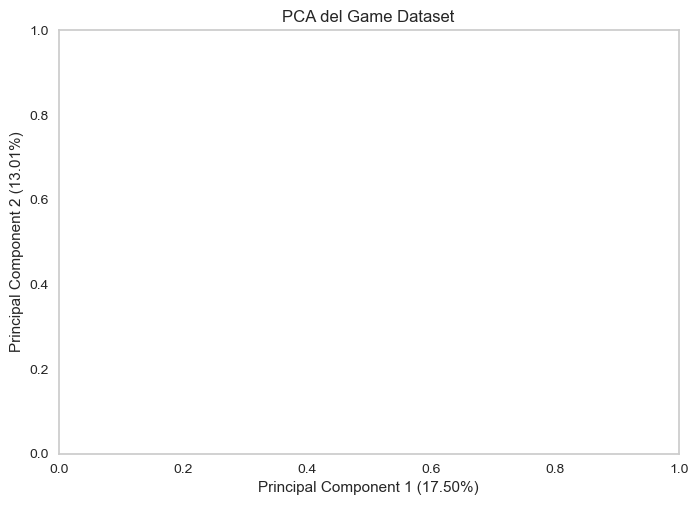

In [18]:
# Calcola la varianza per TUTTE E 3 le componenti
pc1_variance = pca_analisi.explained_variance_ratio_[0] * 100
pc2_variance = pca_analisi.explained_variance_ratio_[1] * 100
pc3_variance = pca_analisi.explained_variance_ratio_[2] * 100

plt.xlabel(f'Principal Component 1 ({pc1_variance:.2f}%)')
plt.ylabel(f'Principal Component 2 ({pc2_variance:.2f}%)')
plt.title('PCA del Game Dataset')
plt.grid()
plt.show()

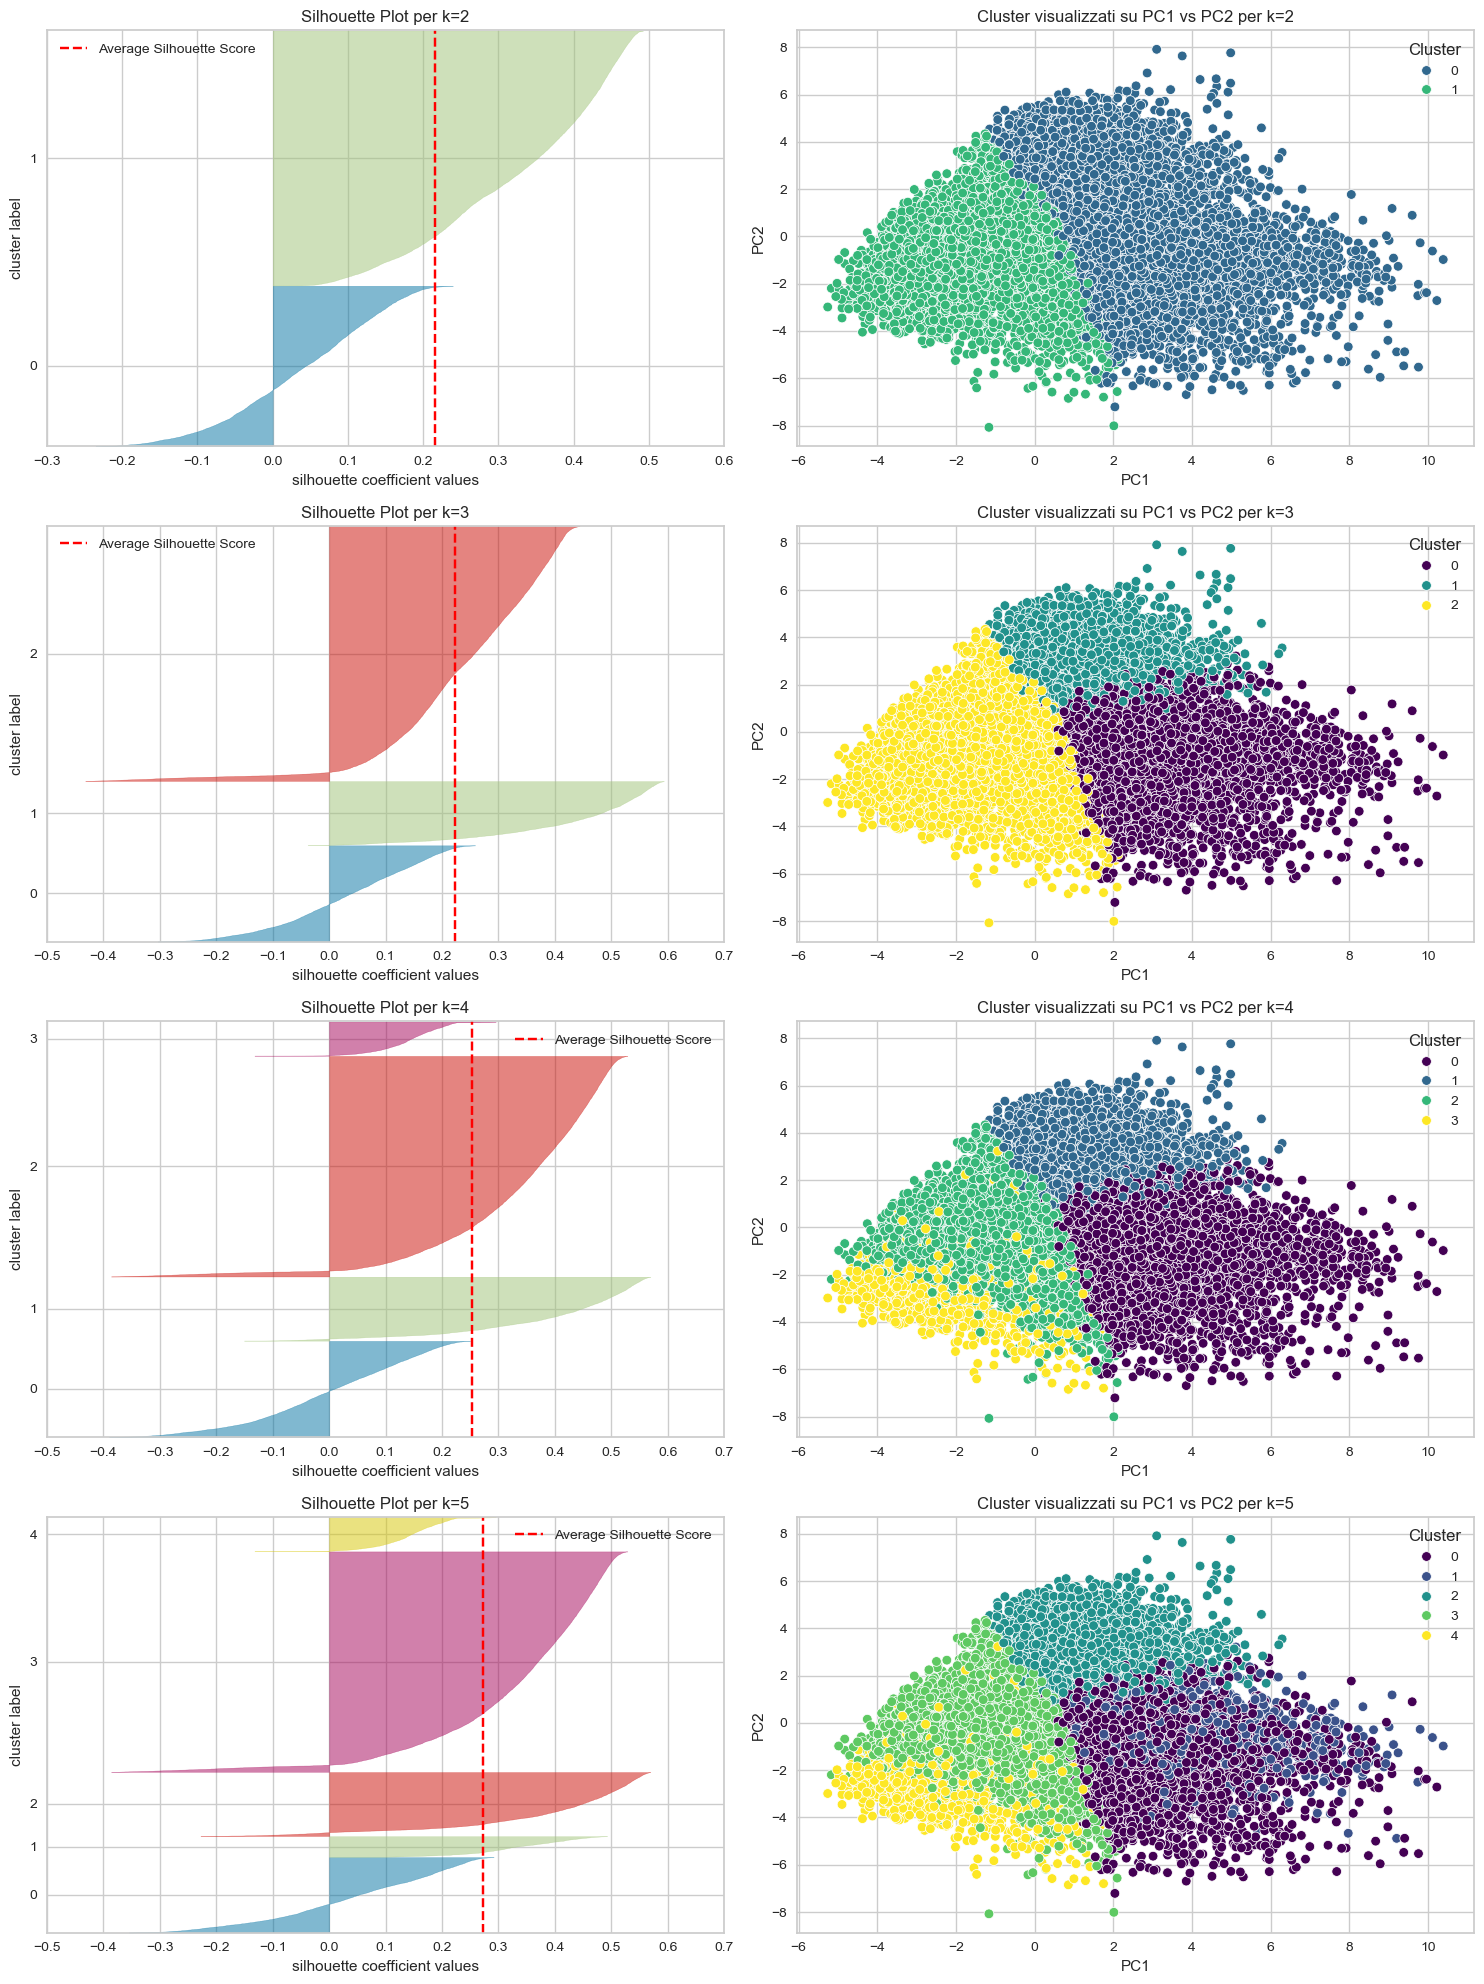

In [16]:
# Inserisci questo codice nel tuo script dopo aver calcolato X_pca

from sklearn.cluster import BisectingKMeans
from yellowbrick.cluster import SilhouetteVisualizer

# --- Analisi Silhouette per Bisecting K-Means ---

# Useremo i dati dopo la PCA, che sono ottimi per il clustering
X_per_clustering = X_train_pca

# Definiamo il numero massimo di cluster da testare
n_clust_max = 6 # Proviamo fino a 5 cluster (range(2, 6) -> 2, 3, 4, 5)

# Creiamo una griglia di subplot. Ogni riga avrà un silhouette plot e uno scatter plot.
# Il numero di righe è n_clust_max - 2
fig, axs = plt.subplots(n_clust_max - 2, 2, figsize=(15, 5 * (n_clust_max - 2)))

for k in range(2, n_clust_max):
    # Indice della riga corrente nei subplot
    riga_idx = k - 2

    # --- Grafico a Sinistra: Silhouette Plot ---
    
    # 1. Crea il modello di clustering
    bkmeans = BisectingKMeans(n_clusters=k, random_state=222)
    
    # 2. Crea il visualizzatore Silhouette
    # Assegniamo il visualizzatore al primo asse (colonna 0) della riga corrente
    visualizer = SilhouetteVisualizer(bkmeans, colors='yellowbrick', ax=axs[riga_idx][0])
    
    # 3. Adatta i dati per generare il grafico
    visualizer.fit(X_per_clustering)
    visualizer.finalize() # Finalizza il grafico
    axs[riga_idx][0].set_title(f'Silhouette Plot per k={k}')

    # --- Grafico a Destra: Scatter Plot dei Cluster ---
    
    # Creiamo un DataFrame con i risultati della PCA per plottare più facilmente
    pca_df_plot = pd.DataFrame(X_per_clustering[:, :2], columns=['PC1', 'PC2'])
    pca_df_plot['cluster'] = bkmeans.labels_

    # 4. Disegna lo scatter plot sul secondo asse (colonna 1)
    sns.scatterplot(
        data=pca_df_plot,
        x='PC1',
        y='PC2',
        hue='cluster',
        palette='viridis', # Puoi scegliere la palette che preferisci
        ax=axs[riga_idx][1]
    )
    axs[riga_idx][1].set_title(f'Cluster visualizzati su PC1 vs PC2 per k={k}')
    axs[riga_idx][1].legend(title='Cluster')

plt.tight_layout()
plt.show()
